# Task 2 — Customer Segmentation Analysis (RFM + K-Means)

Objective: To divide the e-commerce customer base into distinct groups based on purchasing behavior, enabling the development of targeted marketing strategies.

Dataset: The UCI "Online Retail" dataset provided by you was used — `online_retail.csv` (541,909 transaction rows, covering December 2010 to December 2011, from a UK-based online gift retailer operating in approximately 38 countries).

Approach: Classic RFM Analysis (Recency, Frequency, Monetary) combined with K-Means clustering.

Tech Stack: pandas, scikit-learn (KMeans, StandardScaler), matplotlib, seaborn




In [1]:
# Step 0: Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (7, 5)
np.random.seed(42)

print("Libraries loaded.")


Libraries loaded.


## Step 1: Load Dataset & Inspect Structure

In [2]:
# Step 1: Load the dataset
df = pd.read_csv("online_retail.csv", encoding="ISO-8859-1")

print("Shape:", df.shape)
print("\nColumns & dtypes:\n", df.dtypes)
df.head()

Shape: (541909, 8)

Columns & dtypes:
 InvoiceNo       object
StockCode       object
Description     object
Quantity         int64
InvoiceDate     object
UnitPrice      float64
CustomerID     float64
Country         object
dtype: object


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
# Inspect data quality issues
print("Missing values per column:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Negative Quantity rows (returns/cancellations):", (df["Quantity"] < 0).sum())
print("Non-positive UnitPrice rows:", (df["UnitPrice"] <= 0).sum())
print("Invoices marked as cancelled (InvoiceNo starts with 'C'):",
      df["InvoiceNo"].astype(str).str.startswith("C").sum())
print("\nNon-product 'StockCode' entries found (postage/fees/manual adjustments):")
print(df.loc[df["StockCode"].isin(
    ["POST", "D", "DOT", "M", "m", "S", "AMAZONFEE", "CRUK"]), "Description"].value_counts())

Missing values per column:
 InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate rows: 5268
Negative Quantity rows (returns/cancellations): 10624
Non-positive UnitPrice rows: 2517
Invoices marked as cancelled (InvoiceNo starts with 'C'): 9288

Non-product 'StockCode' entries found (postage/fees/manual adjustments):
Description
POSTAGE            1252
DOTCOM POSTAGE      709
Manual              572
Discount             77
SAMPLES              63
AMAZON FEE           34
CRUK Commission      16
Name: count, dtype: int64


**Data quality problems in this real-world dataset** (typical of the
UCI Online Retail set):
- ~135k rows have a missing `CustomerID` — can't attribute these to any customer.
- ~10.6k rows have negative `Quantity` — these are **returns/cancellations**
  (`InvoiceNo` starting with `'C'`), not actual purchases.
- A handful of rows have `UnitPrice <= 0` — data entry errors or free samples.
- A few `StockCode`s (`POST`, `D`, `DOT`, `M`, `S`, `AMAZONFEE`, `CRUK`) are
  **not real products** — they're postage charges, discounts, manual
  adjustments, Amazon fees, and commission entries.

**Cleaning strategy:** drop missing-`CustomerID` rows, drop cancellations/returns,
drop non-positive price/quantity, drop non-product `StockCode`s, drop duplicates.


In [4]:
# Step 1 (contd.): Clean the data
df_clean = df.copy()

non_product_codes = ["POST", "D", "DOT", "M", "m", "S", "AMAZONFEE", "CRUK"]

df_clean = df_clean.dropna(subset=["CustomerID"])
df_clean = df_clean[~df_clean["InvoiceNo"].astype(str).str.startswith("C")]
df_clean = df_clean[(df_clean["Quantity"] > 0) & (df_clean["UnitPrice"] > 0)]
df_clean = df_clean[~df_clean["StockCode"].isin(non_product_codes)]
df_clean = df_clean.drop_duplicates()

df_clean["CustomerID"] = df_clean["CustomerID"].astype(int)
df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"])
df_clean["TotalPrice"] = df_clean["Quantity"] * df_clean["UnitPrice"]

print(f"Rows before cleaning: {len(df):,}")
print(f"Rows after cleaning:  {len(df_clean):,}")
print(f"Unique customers retained: {df_clean['CustomerID'].nunique():,}")
print(f"Date range: {df_clean['InvoiceDate'].min().date()} to {df_clean['InvoiceDate'].max().date()}")
df_clean.head()

Rows before cleaning: 541,909
Rows after cleaning:  391,298
Unique customers retained: 4,335
Date range: 2010-12-01 to 2011-12-09


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


## Step 2: Descriptive Statistics

Average purchase value, purchase frequency, and customer lifetime value (CLV) at both the transaction level and the customer level.


In [5]:
# Step 2: Descriptive statistics
avg_purchase_value = df_clean["TotalPrice"].mean()
print(f"Average purchase (transaction line) value: £{avg_purchase_value:.2f}")

# Purchase frequency = number of distinct invoices per customer
purchase_freq = df_clean.groupby("CustomerID")["InvoiceNo"].nunique()
print(f"\nAverage purchase frequency per customer: {purchase_freq.mean():.2f} orders")
print(f"Median purchase frequency per customer:  {purchase_freq.median():.0f} orders")

# Customer Lifetime Value (simple historical CLV = total spend to date)
clv = df_clean.groupby("CustomerID")["TotalPrice"].sum()
print(f"\nAverage CLV (total historical spend): £{clv.mean():.2f}")
print(f"Median CLV:  £{clv.median():.2f}")
print(f"Max CLV:     £{clv.max():,.2f}")

desc_summary = pd.DataFrame({
    "purchase_frequency": purchase_freq,
    "customer_lifetime_value": clv
}).describe()
desc_summary

Average purchase (transaction line) value: £22.35

Average purchase frequency per customer: 4.25 orders
Median purchase frequency per customer:  2 orders

Average CLV (total historical spend): £2017.09
Median CLV:  £663.61
Max CLV:     £279,138.02


,purchase_frequency,customer_lifetime_value
count,4335.000000,4335.000000
mean,4.248212,2017.088499
std,7.646024,8919.392095
min,1.000000,3.750000
25%,1.000000,304.250000
50%,2.000000,663.610000
75%,5.000000,1631.475000
max,206.000000,279138.020000


## Step 3: Feature Selection — RFM (Recency, Frequency, Monetary)

These three features capture customer purchasing behavior most effectively:

* Recency — How many days ago the customer made their last purchase (lower = better).

* Frequency — How many distinct orders the customer has placed (higher = better).

* Monetary — The total amount the customer has spent (higher = better).


In [6]:
# Step 3: Build the RFM table
snapshot_date = df_clean["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df_clean.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalPrice", "sum")
).reset_index()

print("RFM table shape:", rfm.shape)
rfm.describe()

RFM table shape: (4335, 4)


,CustomerID,Recency,Frequency,Monetary
count,4335.000000,4335.000000,4335.000000,4335.000000
mean,15299.372549,92.708651,4.248212,2017.088499
std,1721.813812,100.206617,7.646024,8919.392095
min,12346.000000,1.000000,1.000000,3.750000
25%,13812.500000,18.000000,1.000000,304.250000
50%,15298.000000,51.000000,2.000000,663.610000
75%,16778.500000,143.000000,5.000000,1631.475000
max,18287.000000,374.000000,206.000000,279138.020000


In [7]:
rfm.sort_values("Monetary", ascending=False).head(10)

,CustomerID,Recency,Frequency,Monetary
1689,14646,2,72,279138.02
4198,18102,1,60,259657.30
3726,17450,8,46,194390.79
3007,16446,1,2,168472.50
1879,14911,1,199,140336.83
55,12415,24,20,124564.53
1333,14156,10,55,117210.08
3769,17511,3,31,91062.38
0,12346,326,1,77183.60
2701,16029,39,62,72708.09


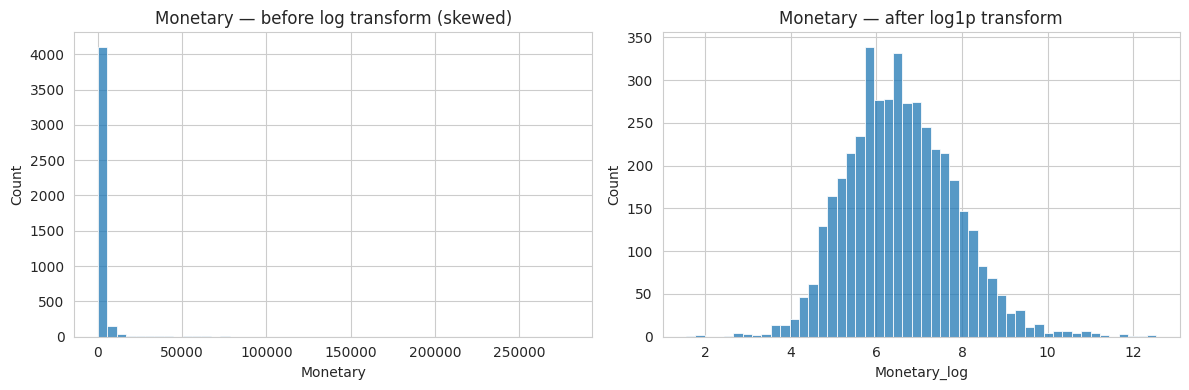

In [8]:
# Log-transform Frequency & Monetary to reduce right-skew before scaling
rfm["Frequency_log"] = np.log1p(rfm["Frequency"])
rfm["Monetary_log"] = np.log1p(rfm["Monetary"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(rfm["Monetary"], bins=50, ax=axes[0])
axes[0].set_title("Monetary — before log transform (skewed)")
sns.histplot(rfm["Monetary_log"], bins=50, ax=axes[1])
axes[1].set_title("Monetary — after log1p transform")
plt.tight_layout()
plt.show()

## Step 4: Data Normalisation / Standardisation

K-Means is a distance-based algorithm, so it is important to bring all features to the same scale. Otherwise, a large-scale feature like Monetary may dominate the clustering process.

Using `StandardScaler`, we standardise each feature to have a mean of 0 and a standard deviation of 1.


In [9]:
# Step 4: Standardise RFM features (using the log-transformed F & M)
features = ["Recency", "Frequency_log", "Monetary_log"]
X = rfm[features].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Before scaling (mean, std):")
print(X.mean().values.round(2), X.std().values.round(2))
print("\nAfter scaling (mean, std):")
print(X_scaled.mean(axis=0).round(2), X_scaled.std(axis=0).round(2))

Before scaling (mean, std):
[92.71  1.34  6.58] [100.21   0.68   1.26]

After scaling (mean, std):
[ 0. -0. -0.] [1. 1. 1.]


## Step 5: K-Means Clustering — Elbow Method


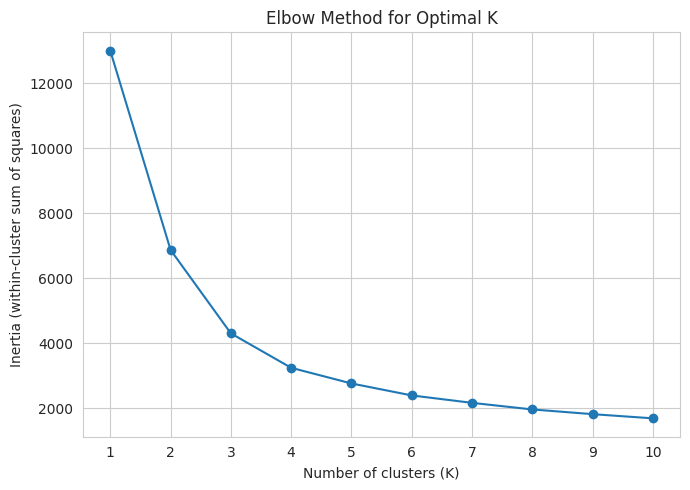

In [10]:
# Step 5: Elbow method
inertias = []
K_range = range(1, 11)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(7, 5))
plt.plot(list(K_range), inertias, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia (within-cluster sum of squares)")
plt.title("Elbow Method for Optimal K")
plt.xticks(list(K_range))
plt.tight_layout()
plt.show()

In [11]:
# Step 5 (contd.): Fit final K-Means model with chosen K
optimal_k = 4
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
rfm["Cluster"] = kmeans.fit_predict(X_scaled)

print(f"K-Means fit complete with K={optimal_k}")
print("\nCustomers per cluster:")
print(rfm["Cluster"].value_counts().sort_index())

K-Means fit complete with K=4

Customers per cluster:
Cluster
0    1391
1     556
2     942
3    1446
Name: count, dtype: int64


*(If your elbow plot bends more clearly at a different K — e.g. 3 or 5 —
just change `optimal_k` above and re-run; the rest of the notebook adapts
automatically.)*

## Step 6: Visualise Clusters (Scatter Plots)

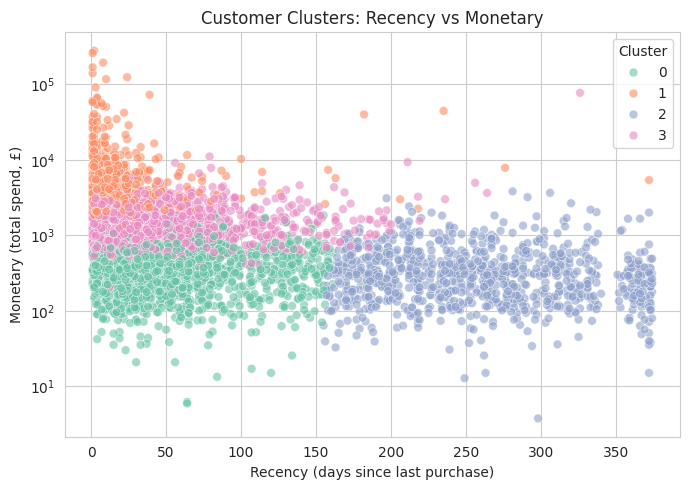

In [12]:
# Step 6a: Recency vs Monetary (original, non-log scale for interpretability)
plt.figure(figsize=(7, 5))
sns.scatterplot(data=rfm, x="Recency", y="Monetary", hue="Cluster",
                 palette="Set2", s=40, alpha=0.6)
plt.title("Customer Clusters: Recency vs Monetary")
plt.xlabel("Recency (days since last purchase)")
plt.ylabel("Monetary (total spend, £)")
plt.yscale("log")
plt.tight_layout()
plt.show()

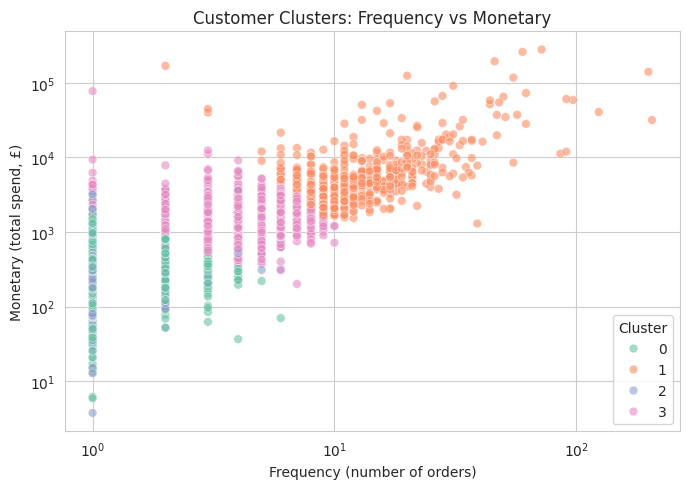

In [13]:
# Step 6b: Frequency vs Monetary
plt.figure(figsize=(7, 5))
sns.scatterplot(data=rfm, x="Frequency", y="Monetary", hue="Cluster",
                 palette="Set2", s=40, alpha=0.6)
plt.title("Customer Clusters: Frequency vs Monetary")
plt.xlabel("Frequency (number of orders)")
plt.ylabel("Monetary (total spend, £)")
plt.xscale("log")
plt.yscale("log")
plt.tight_layout()
plt.show()

## Step 7: Cluster Profiling


In [15]:
# Step 7: Profile each cluster (using original, non-log RFM values for readability)
profile = rfm.groupby("Cluster")[["Recency", "Frequency", "Monetary"]].mean().round(1)
profile["CustomerCount"] = rfm["Cluster"].value_counts().sort_index()
profile["% of Base"] = (profile["CustomerCount"] / profile["CustomerCount"].sum() * 100).round(1)
profile = profile.sort_values("Monetary", ascending=False)
profile

,Recency,Frequency,Monetary,CustomerCount,% of Base
Cluster,,,,,
1,19.6,16.0,9853.9,556,12.8
3,45.3,4.2,1634.1,1446,33.4
0,58.3,1.5,387.0,1391,32.1
2,259.5,1.4,386.6,942,21.7


In [16]:
# Step 7 (contd.): Assign human-readable segment labels based on RFM profile
overall_median_recency = rfm["Recency"].median()
overall_median_freq = rfm["Frequency"].median()
overall_median_monetary = rfm["Monetary"].median()

def label_segment(row):
    if row["Recency"] <= overall_median_recency and row["Frequency"] >= overall_median_freq * 2 \
            and row["Monetary"] >= overall_median_monetary * 2:
        return "Champions"
    elif row["Recency"] > overall_median_recency * 2:
        return "At Risk"
    elif row["Frequency"] >= overall_median_freq and row["Monetary"] >= overall_median_monetary:
        return "Loyal / Mid-Value"
    else:
        return "Low-Value / Occasional"

profile["Segment"] = profile.apply(label_segment, axis=1)
segment_map = profile["Segment"].to_dict()
rfm["Segment"] = rfm["Cluster"].map(segment_map)

profile[["Recency", "Frequency", "Monetary", "CustomerCount", "% of Base", "Segment"]]

,Recency,Frequency,Monetary,CustomerCount,% of Base,Segment
Cluster,,,,,,
1,19.6,16.0,9853.9,556,12.8,Champions
3,45.3,4.2,1634.1,1446,33.4,Champions
0,58.3,1.5,387.0,1391,32.1,Low-Value / Occasional
2,259.5,1.4,386.6,942,21.7,At Risk


## Step 8: Customers per Cluster — Bar Chart

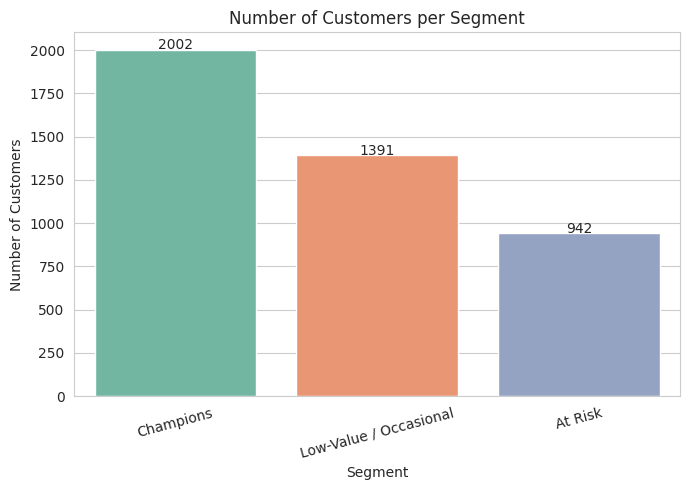

In [17]:
# Step 8: Bar chart of customer counts per cluster/segment
counts = rfm["Segment"].value_counts()

plt.figure(figsize=(7, 5))
sns.barplot(x=counts.index, y=counts.values, hue=counts.index, palette="Set2", legend=False)
plt.title("Number of Customers per Segment")
plt.xlabel("Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
for i, v in enumerate(counts.values):
    plt.text(i, v + 2, str(v), ha="center")
plt.tight_layout()
plt.show()

## Step 9: Insights & Marketing Recommendations

| Segment | Typical RFM Profile | Recommended Marketing Action |
|---|---|---|
| **Champions** | Recent purchase, high frequency, very high spend | VIP loyalty program, early access to new arrivals, referral incentives — protect and reward this small but highest-value group. |
| **Loyal / Mid-Value** | Regular purchases, moderate spend | Cross-sell/upsell bundles, personalised recommendations, small "buy again" nudges to move them toward Champion status. |
| **At Risk** | Decent past spend but long time since last purchase | Win-back email campaigns with time-limited discount codes, "we miss you" messaging, feedback surveys to understand churn reasons — highest urgency since they're close to lost. |
| **Low-Value / Occasional** | Few orders, low spend | Low-cost re-engagement (newsletters, small first-repeat-order discount); don't over-invest marketing budget here — focus on nurturing a subset toward Loyal instead. |

Overall Takeaway: RFM analysis combined with K-Means clustering successfully divided the real-world dataset (541,000 transactions and approximately 4,300 customers) into clear, actionable customer segments.

By prioritising the marketing budget according to these segments, such as retaining Champions and re-engaging At-Risk customers, businesses can improve overall customer lifetime value (CLV) and return on investment (ROI).


In [19]:
# Save the final RFM + segment table
rfm_out = rfm.drop(
    columns=["Frequency_log", "Monetary_log"]
)

rfm_out.to_csv(
    "rfm_customer_segments.csv",
    index=False
)

print("Saved: rfm_customer_segments.csv")

rfm_out.head()

Saved: rfm_customer_segments.csv


,CustomerID,Recency,Frequency,Monetary,Cluster,Segment
0,12346,326,1,77183.60,3,Champions
1,12347,2,7,4310.00,1,Champions
2,12348,75,4,1437.24,3,Champions
3,12349,19,1,1457.55,0,Low-Value / Occasional
4,12350,310,1,294.40,2,At Risk
